# 13 — Temporal Issue Validation (máy local)

**Mục đích**

Với mỗi issue group của RQ2, đánh giá bằng chứng theo thời gian để biết issue còn xuất hiện trong bối cảnh sản phẩm hiện tại hay đã
giảm mạnh (ĐC §7.5): ACTIVE, RECURRING, POSSIBLY_RESOLVED hoặc INSUFFICIENT_EVIDENCE. Mặc định chỉ ACTIVE và RECURRING được chuyển sang
sinh requirement ở GĐ14.

**Luật đã pre-register**

Luật, cửa sổ và tham số đọc từ `03_configs/frozen/temporal_config.yaml` (amendment v2.5), được chốt sau EDA thời gian ở mức toàn
corpus và trước khi tính trạng thái của bất kỳ cụm nào. Notebook không chỉnh tham số; các giá trị khác chỉ xuất hiện trong phần độ nhạy.

**Đầu vào**

Kết quả gom cụm đã khóa ở amendment v2.4 (`topics.csv`, `review_topic_map.csv`, đối chiếu sha256) và ngày, phiên bản của review trong
`actionable_reviews.csv`.

**Issue group**

Mỗi cụm (trừ outlier); với cụm `mixed`, thêm mỗi nhóm con (cụm × loại) thuộc mixed-origin của Q14 — đó là đơn vị sinh requirement của
cụm mixed ở GĐ14.

In [1]:
import os, sys, json, hashlib, datetime, subprocess
import numpy as np, pandas as pd, yaml
ROOT = os.path.abspath('..')
sys.path.insert(0, os.path.join(ROOT, '02_src'))
from src.utils.seeds import set_seed
set_seed(42)
from IPython.display import Image, display
from src.utils.display import show as show_table
from src.temporal import core as TC
from src.reporting import figures as RF
RES = os.path.join(ROOT, '05_experiments', 'rq2_topics')
CFG = TC.load_config(ROOT)
COMMIT = subprocess.run(['git', '-C', ROOT, 'rev-parse', 'HEAD'], capture_output=True, text=True).stdout.strip()
print('Ngày chạy:', datetime.date.today().strftime('%d/%m/%Y'), '| commit:', COMMIT)
print('T0:', TC.t0(CFG), '| luật:', CFG['rule'])

Ngày chạy: 01/11/2026 | commit: 421f3cc13ad1e4880ebffa5d2818ca7b5dadbd5e
T0: 2026-10-06 23:59:59+07:00 | luật: {'min_n': 20, 'min_c30': 5, 'min_r90': 0.5, 'presence_min_reviews': 3, 'recurring_min_windows': 6}


## Dữ liệu và đối chiếu

**Kết quả gom cụm đã khóa**

`topics.csv` và `review_topic_map.csv` phải trùng sha256 ghi trong `03_configs/frozen/rq2_topics_config.yaml`; khác thì dừng.

**B90 của corpus**

B90 được tính lại từ ngày của 10.897 review actionable và phải trùng giá trị đã pre-register (0,2742).

In [2]:
FZ12 = yaml.safe_load(open(os.path.join(ROOT, '03_configs', 'frozen', 'rq2_topics_config.yaml'), encoding='utf-8'))['rq2_topics']
for f in ('topics.csv', 'review_topic_map.csv'):
    h = hashlib.sha256(open(os.path.join(RES, f), 'rb').read()).hexdigest()
    assert h == FZ12['locked_result']['files_sha256'][f], f'{f} khác kết quả đã khóa (v2.4)'
TOPICS = pd.read_csv(os.path.join(RES, 'topics.csv'), encoding='utf-8-sig')
MAP = pd.read_csv(os.path.join(RES, 'review_topic_map.csv'))
ACT = pd.read_csv(os.path.join(RES, 'actionable_reviews.csv'), encoding='utf-8-sig', usecols=['review_id', 'review_date', 'app_version'])
assert len(ACT) == len(MAP) == 10897
B90 = TC.corpus_b90(TC.local_dates(ACT['review_date'], CFG), CFG)
print(f"B90 tính lại: {B90:.6f} | pre-register: {CFG['b90']}")
assert abs(B90 - CFG['b90']) < 5e-5, 'B90 khác giá trị đã pre-register'
NAMES = dict(zip(TOPICS['topic_id'].astype(int), TOPICS['name_vi'].fillna(TOPICS['keyword_name'])))
print('Kết quả gom cụm trùng bản đã khóa; B90 trùng giá trị đã pre-register.')

B90 tính lại: 0.274204 | pre-register: 0.2742
Kết quả gom cụm trùng bản đã khóa; B90 trùng giá trị đã pre-register.


## Bằng chứng và trạng thái của từng issue group

**Cột**

N (review trong 12 cửa sổ 30 ngày), c30 / c60 / c90, R90, số cửa sổ có ít nhất 3 review (n_win), first_seen / last_seen, phiên bản đầu
và cuối (chỉ báo cáo; app_version thiếu ở nhiều review), historical frequency (số review của group / 10.897) và trạng thái theo luật
đã pre-register.

In [3]:
GROUPS, SENS = TC.sensitivity(MAP, ACT, TOPICS, CFG)
GROUPS['tên cụm'] = GROUPS['topic_id'].map(NAMES)
view = GROUPS.assign(first_seen=GROUPS['first_seen'].dt.strftime('%d/%m/%Y'), last_seen=GROUPS['last_seen'].dt.strftime('%d/%m/%Y'))
cols = ['group_id', 'tên cụm', 'type', 'N', 'c30', 'c60', 'c90', 'R90', 'n_win', 'first_seen', 'last_seen', 'historical_frequency', 'status']
show_table(view[view['type'] == 'ALL'][cols], 'Issue group cấp cụm — bằng chứng thời gian và trạng thái', decimals=2,
           percent=['historical_frequency'])
show_table(view[view['type'] != 'ALL'][cols], 'Nhóm con (cụm mixed × loại, Q14) — bằng chứng thời gian và trạng thái', decimals=2,
           percent=['historical_frequency'])

group_id,tên cụm,type,N,c30,c60,c90,R90,n_win,first_seen,last_seen,historical_frequency,status
T0,Dịch vụ giao hàng kém chất lượng,ALL,1.214,99,208,314,"0,94",12,06/10/2025,05/10/2026,"11,3%",RECURRING
T1,Lỗi tài khoản và thanh toán,ALL,1.075,65,146,289,"0,98",12,06/10/2025,05/10/2026,"10,1%",RECURRING
T2,Quảng cáo gây phiền phức,ALL,1.291,113,236,381,"1,08",12,06/10/2025,05/10/2026,"12,1%",RECURRING
T3,Quảng cáo xuất hiện liên tục,ALL,1.264,108,243,337,"0,97",12,06/10/2025,06/10/2026,"11,8%",RECURRING
T4,Video tự phát âm thanh phiền phức,ALL,560,56,93,144,"0,94",12,06/10/2025,06/10/2026,"5,3%",RECURRING
T5,Quảng cáo rác và khó chịu,ALL,631,50,116,171,"0,99",12,08/10/2025,06/10/2026,"5,8%",RECURRING
T6,Ứng dụng lag và chậm,ALL,433,34,63,108,"0,91",12,08/10/2025,05/10/2026,"4,0%",RECURRING
T7,Lỗi trong giỏ hàng và mua sắm,ALL,513,46,97,152,"1,08",12,07/10/2025,05/10/2026,"4,7%",RECURRING
T8,Chất lượng sản phẩm và giao hàng,ALL,439,36,74,112,"0,93",12,06/10/2025,05/10/2026,"4,1%",RECURRING
T9,Quảng cáo nhảy vào ứng dụng,ALL,415,37,71,120,"1,05",12,06/10/2025,06/10/2026,"3,9%",RECURRING


group_id,tên cụm,type,N,c30,c60,c90,R90,n_win,first_seen,last_seen,historical_frequency,status
T0-BUG,Dịch vụ giao hàng kém chất lượng,BUG,504,38,82,124,"0,90",12,06/10/2025,03/10/2026,"4,7%",RECURRING
T0-FEATURE,Dịch vụ giao hàng kém chất lượng,FEATURE,682,58,122,182,"0,97",12,06/10/2025,05/10/2026,"6,4%",RECURRING
T0-UX,Dịch vụ giao hàng kém chất lượng,UX,28,3,4,8,"1,04",7,16/10/2025,25/09/2026,"0,3%",INSUFFICIENT_EVIDENCE
T2-BUG,Quảng cáo gây phiền phức,BUG,603,42,88,163,"0,99",12,06/10/2025,05/10/2026,"5,7%",RECURRING
T2-FEATURE,Quảng cáo gây phiền phức,FEATURE,91,8,14,22,"0,88",12,08/10/2025,28/09/2026,"0,9%",RECURRING
T2-UX,Quảng cáo gây phiền phức,UX,597,63,134,196,"1,20",12,07/10/2025,05/10/2026,"5,6%",RECURRING
T4-BUG,Video tự phát âm thanh phiền phức,BUG,125,8,18,30,"0,88",12,08/10/2025,03/10/2026,"1,2%",RECURRING
T4-FEATURE,Video tự phát âm thanh phiền phức,FEATURE,276,29,47,72,"0,95",12,06/10/2025,04/10/2026,"2,6%",RECURRING
T4-UX,Video tự phát âm thanh phiền phức,UX,159,19,28,42,"0,96",12,09/10/2025,06/10/2026,"1,5%",RECURRING
T7-BUG,Lỗi trong giỏ hàng và mua sắm,BUG,242,20,44,67,"1,01",12,10/10/2025,01/10/2026,"2,2%",RECURRING


## Tổng hợp trạng thái

**Chỉ số**

Số group theo trạng thái (cấp cụm và nhóm con), số group đủ điều kiện sinh requirement, và temporal evidence coverage — tỷ lệ group có
đủ bằng chứng để kết luận (không phải INSUFFICIENT_EVIDENCE), một chỉ số của protocol (mục RQ2).

In [4]:
rows = []
for name, g in (('Cấp cụm', GROUPS[GROUPS['type'] == 'ALL']), ('Nhóm con của cụm mixed', GROUPS[GROUPS['type'] != 'ALL'])):
    c = g['status'].value_counts().reindex(TC.STATUSES, fill_value=0)
    rows.append({'mức': name, 'số group': len(g), **c.to_dict(), 'đủ điều kiện sinh requirement': int(g['eligible_for_generation'].sum()),
                 'temporal evidence coverage': float((g['status'] != 'INSUFFICIENT_EVIDENCE').mean()) if len(g) else float('nan')})
SUMMARY = pd.DataFrame(rows)
show_table(SUMMARY, 'Số issue group theo trạng thái temporal', percent=['temporal evidence coverage'])

mức,số group,ACTIVE,RECURRING,POSSIBLY_RESOLVED,INSUFFICIENT_EVIDENCE,đủ điều kiện sinh requirement,temporal evidence coverage
Cấp cụm,17,0,17,0,0,17,"100,0%"
Nhóm con của cụm mixed,15,0,14,0,1,14,"93,3%"


## Độ nhạy

**Cách làm**

Đổi từng tham số một theo các giá trị đã pre-register (c30 ∈ {3, 10}, R90 ∈ {0,4; 0,6}, n_win ∈ {4, 8}), giữ nguyên các tham số khác;
đếm số group theo trạng thái và số group đổi trạng thái so với luật chính. Kết quả chỉ để báo cáo, luật chính không đổi.

In [5]:
show_table(SENS, 'Độ nhạy của trạng thái temporal theo từng tham số')

tham số,giá trị,ACTIVE,RECURRING,POSSIBLY_RESOLVED,INSUFFICIENT_EVIDENCE,số group đổi trạng thái
luật chính,,0,31,0,1,0
min_c30,3,0,32,0,0,1
min_c30,10,0,26,0,6,5
min_r90,"0,400",0,31,0,1,0
min_r90,"0,600",0,31,0,1,0
recurring_min_windows,4,0,31,0,1,0
recurring_min_windows,8,0,31,0,1,0


## Hình: phân bố theo thời gian của từng cụm

**Nội dung**

Hàng là cụm, cột là 12 cửa sổ 30 ngày từ cũ đến mới; màu là tỷ lệ review của cụm rơi vào cửa sổ, số là số review; bên phải là trạng
thái và N. Hình lưu vào `05_experiments/rq2_topics/figures/fig_gd13_temporal_heatmap.png`.

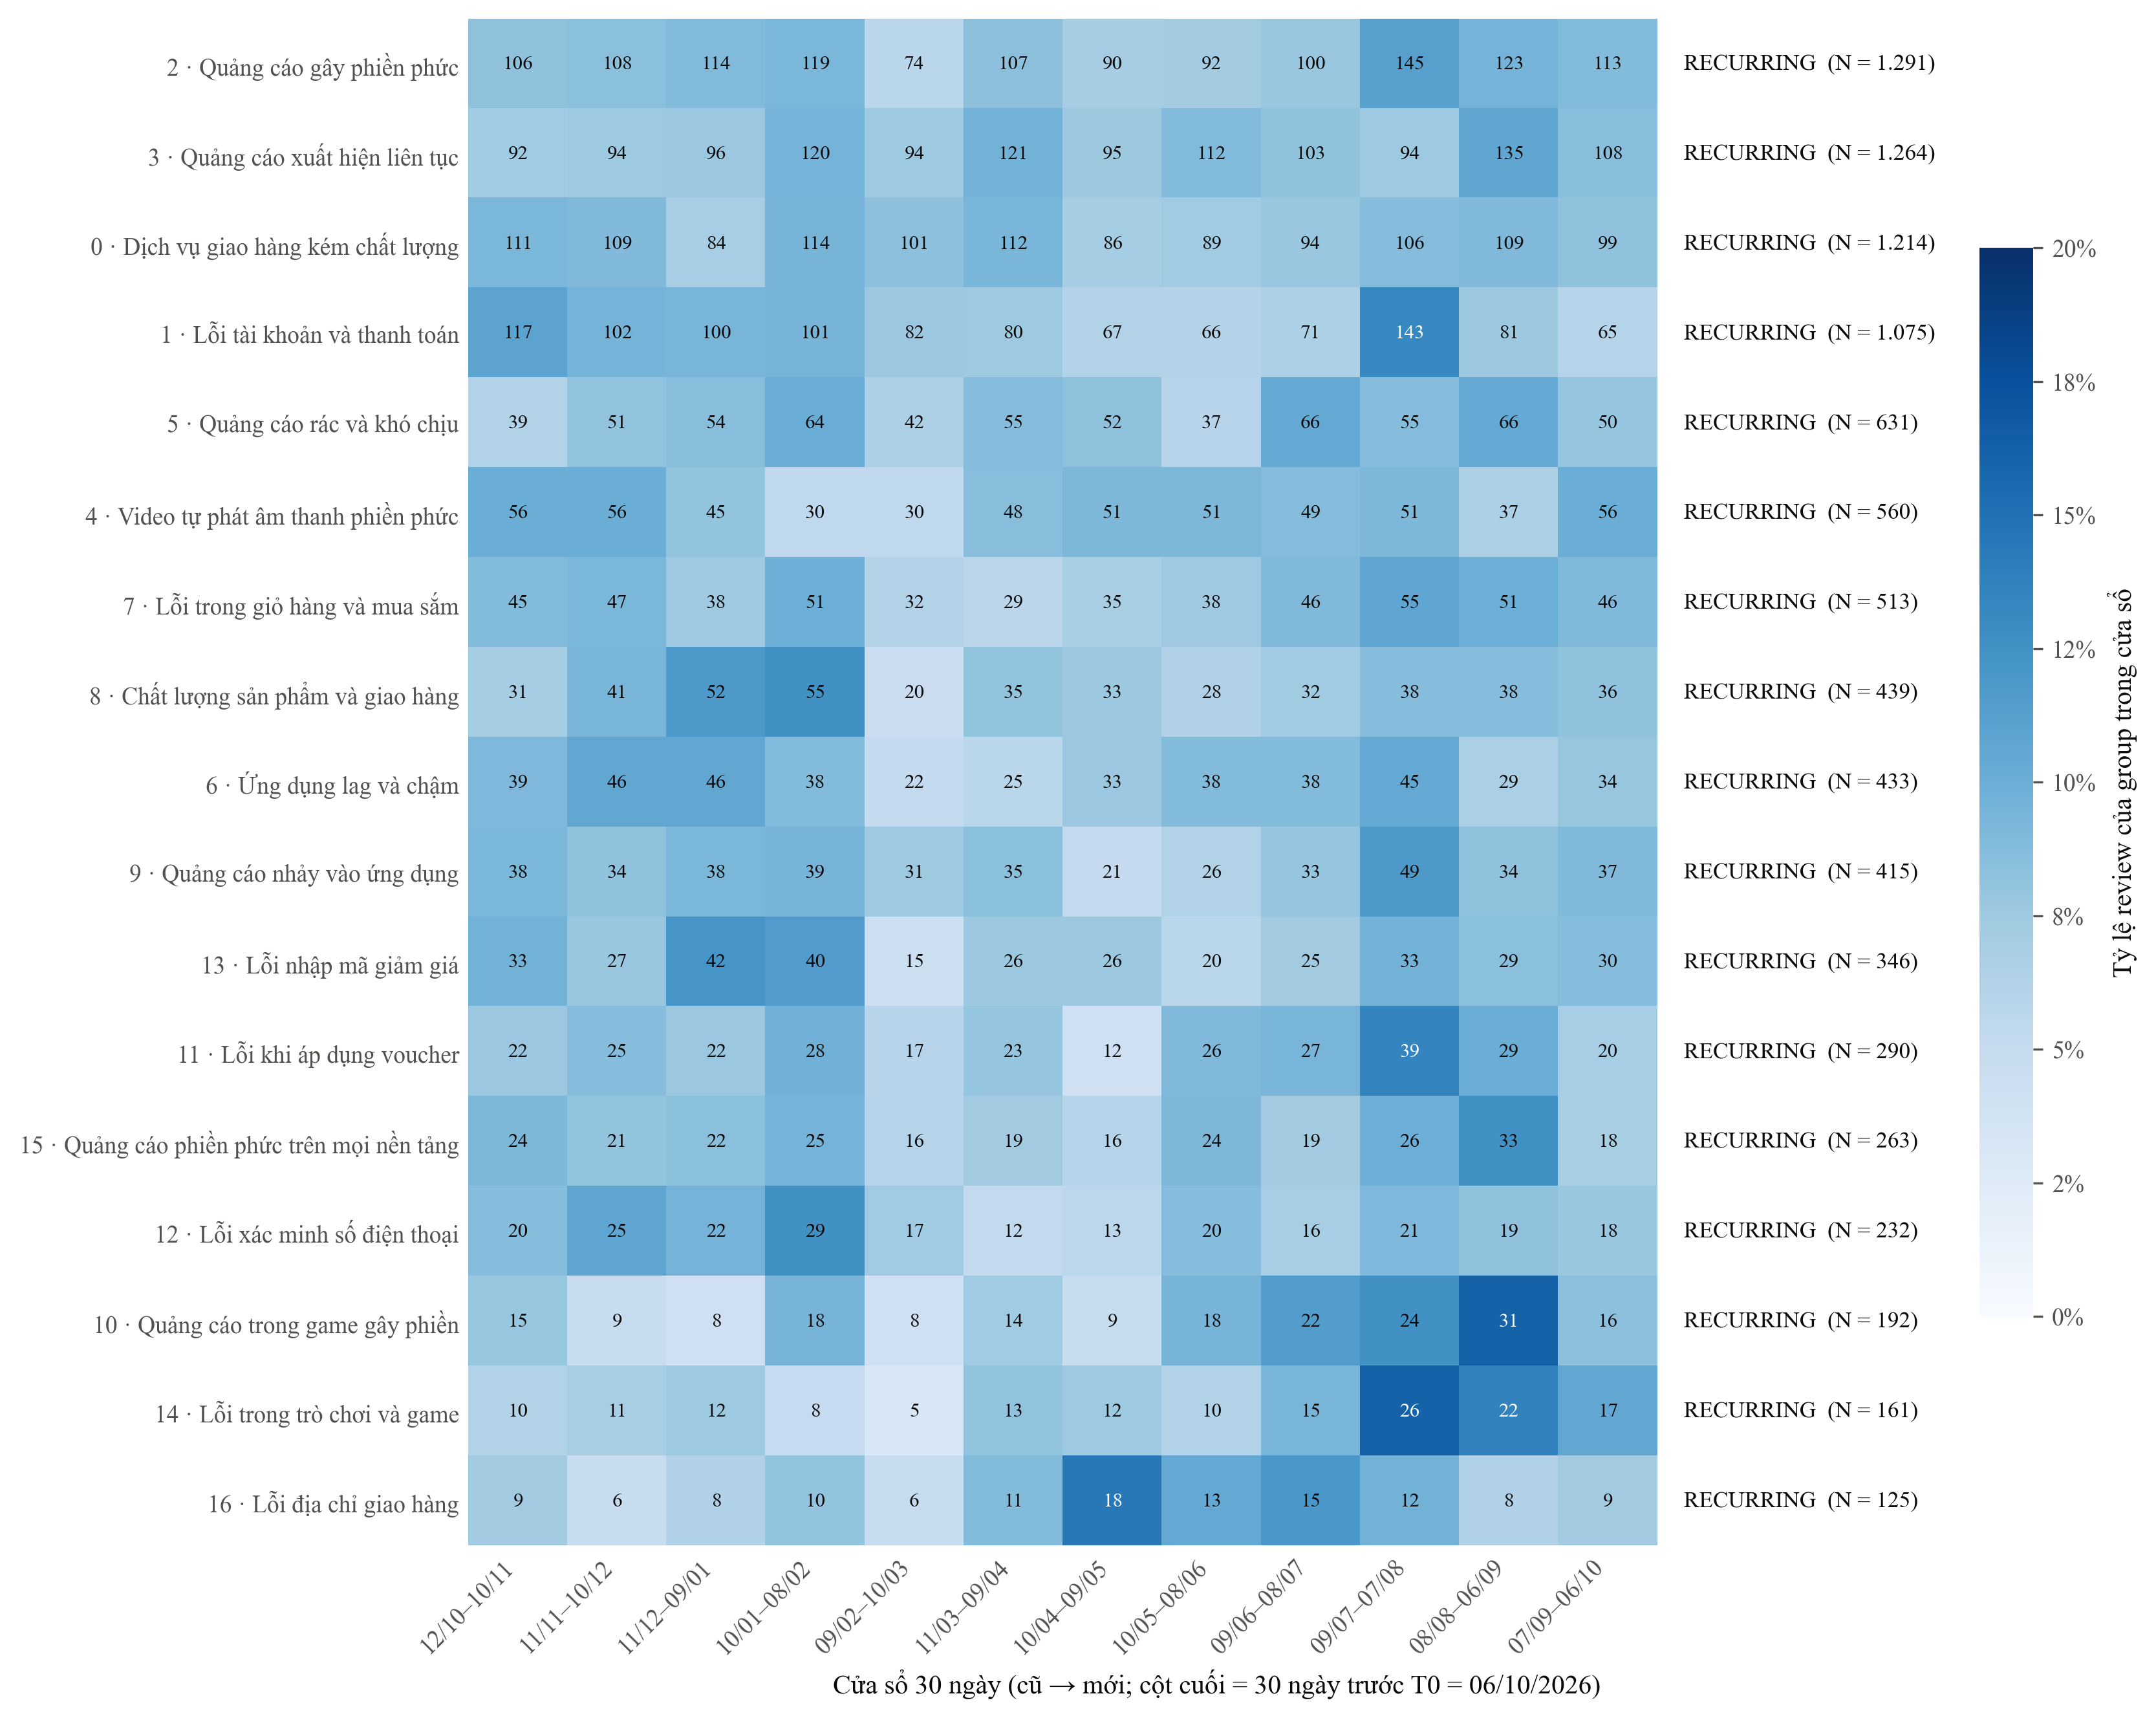

In [6]:
FIGD = os.path.join(RES, 'figures')
os.makedirs(FIGD, exist_ok=True)
TOP = GROUPS[GROUPS['type'] == 'ALL'].sort_values('N', ascending=False)
p = RF.fig_temporal_heatmap(TOP, NAMES, TC.window_labels(CFG), os.path.join(FIGD, 'fig_gd13_temporal_heatmap.png'))
display(Image(filename=p, width=950))

## Lưu kết quả

**File (`05_experiments/rq2_topics/`)**

`gd13_temporal_groups.csv` (một dòng mỗi issue group, không có văn bản review), `gd13_temporal_summary.csv`, `gd13_sensitivity.csv`,
`gd13_run_info.json`.

In [7]:
out = GROUPS.drop(columns=['tên cụm']).copy()
out['per_window_W0_to_W11'] = out.pop('per_window').map(lambda w: ';'.join(map(str, w)))
for c in ('first_seen', 'last_seen'):
    out[c] = out[c].dt.strftime('%Y-%m-%d %H:%M:%S%z')
out.to_csv(os.path.join(RES, 'gd13_temporal_groups.csv'), index=False)
SUMMARY.to_csv(os.path.join(RES, 'gd13_temporal_summary.csv'), index=False)
SENS.to_csv(os.path.join(RES, 'gd13_sensitivity.csv'), index=False)
json.dump({'run_date': datetime.date.today().isoformat(), 'commit': COMMIT, 'b90_recomputed': B90, 'config': CFG,
           'n_groups': len(GROUPS), 'n_topic_groups': int((GROUPS['type'] == 'ALL').sum()),
           'status_counts': GROUPS['status'].value_counts().to_dict(),
           'n_eligible': int(GROUPS['eligible_for_generation'].sum())},
          open(os.path.join(RES, 'gd13_run_info.json'), 'w', encoding='utf-8'), indent=1, ensure_ascii=False, default=str)
print('Đã lưu:', sorted(f for f in os.listdir(RES) if f.startswith('gd13_')))

Đã lưu: ['gd13_run_info.json', 'gd13_sensitivity.csv', 'gd13_temporal_groups.csv', 'gd13_temporal_summary.csv']


## Nhận xét

**Nguồn số liệu**

Mọi số dưới đây lấy từ `gd13_temporal_groups.csv`, `gd13_temporal_summary.csv`, `gd13_sensitivity.csv` và `gd13_run_info.json` trong
`05_experiments/rq2_topics/`. Luật là luật đã pre-register ở amendment v2.5; không tham số nào được chỉnh sau khi xem kết quả.

**Đối chiếu đầu vào**

`topics.csv` và `review_topic_map.csv` trùng sha256 của kết quả đã khóa (v2.4). B90 tính lại từ 10.897 review actionable là 0,27420, trùng
giá trị đã pre-register.

**Kết quả**

Cả 17 cụm đều là RECURRING. Trong 15 nhóm con (cụm mixed × loại, Q14), 14 nhóm là RECURRING và 1 nhóm là INSUFFICIENT_EVIDENCE: nhóm UX
của cụm 0 (giao hàng) có N = 28 nhưng chỉ 3 review trong 30 ngày cuối, dưới ngưỡng 5. Không group nào là ACTIVE hay POSSIBLY_RESOLVED.
Temporal evidence coverage là 100% ở cấp cụm và 93,3% ở nhóm con; 31 trên 32 group đủ điều kiện sinh requirement theo luật mặc định.

**Vì sao mọi cụm đều RECURRING**

Mọi cụm có ít nhất 3 review ở cả 12 cửa sổ 30 ngày (nhóm con: 7 đến 12 cửa sổ), và R90 của các group nằm trong khoảng 0,72 (nhóm FEATURE
của cụm 9) đến 1,47 (cụm 14), tức không group nào giảm xuống dưới một nửa mức nền của corpus. Các issue này xuất hiện đều đặn suốt cửa sổ
12 tháng. Với các cụm lớn (từ 125 review) và lượng review khá đều theo thời gian, luật temporal ở cấp cụm không loại issue nào; vai trò
lọc của bước này nhỏ trên dữ liệu hiện tại. Đây là kết quả của luật đã pre-register, không phải lý do để đổi luật.

**Độ nhạy**

Đổi R90 sang 0,4 hoặc 0,6, hay n_win sang 4 hoặc 8, không làm group nào đổi trạng thái. Hạ c30 xuống 3 làm nhóm UX của cụm 0 thành
RECURRING. Nâng c30 lên 10 làm 5 group chuyển sang INSUFFICIENT_EVIDENCE: nhóm FEATURE của cụm 2 (8 review trong 30 ngày cuối), nhóm BUG
của cụm 4 (8), nhóm FEATURE của cụm 7 (5), nhóm FEATURE của cụm 9 (6) và cụm 16 (9). Kết luận "mọi cụm vẫn còn xuất hiện" vững với các
ngưỡng hợp lý; chỉ các nhóm nhỏ nhạy với ngưỡng số review gần đây.

**Tín hiệu gần đây (chỉ mô tả)**

R90 cao nhất ở cụm 14 (trò chơi trong Shopee, 1,47), cụm 10 (quảng cáo trong game, 1,35) và nhóm UX của cụm 9 (1,22) và cụm 2 (1,20):
tỷ lệ review của các group này rơi vào 90 ngày cuối cao hơn mức của toàn corpus. Heatmap cho thấy cửa sổ 09/07–07/08 tăng ở nhiều cụm
(cụm 2: 145 review, cụm 1: 143, cụm 11: 39, cụm 14: 26); cụm 16 (địa chỉ giao hàng, từ khóa "phường", "xã", "sáp_nhập") tập trung ở các
cửa sổ từ 10/04 đến 08/07. Đây là liên hệ theo thời gian, không phải kết luận về nguyên nhân.

**Phiên bản ứng dụng**

Tỷ lệ review có app_version của các cụm từ 56% đến 83%; phiên bản cuối cùng ghi nhận của 13 trên 17 cụm là 3.82.59. Phiên bản chỉ được báo
cáo, không dùng trong luật (amendment v2.5); không có kết luận issue nào đã được sửa sau một bản cập nhật.

**Giới hạn**

Cửa sổ lịch sử chỉ 12 tháng và review gần T0 hiển thị trễ (ngày 06/10/2026 chỉ có 4 review). Trạng thái RECURRING của các cụm có manual
purity thấp (ví dụ cụm 2, 9) nói về một tập than phiền lẫn nhiều vấn đề chứ không về một issue cụ thể. Recall tầng 1 trên Hold-out 69,8
± 4,0 nên số review của mỗi group thấp hơn số thật; luật dựa trên tỷ lệ so với corpus nên ít bị ảnh hưởng hơn số tuyệt đối. Review chỉ
phản ánh người dùng viết review, không phải toàn bộ người dùng.

**File kết quả**

`gd13_temporal_groups.csv` (một dòng mỗi group, kèm số review theo 12 cửa sổ), `gd13_temporal_summary.csv`, `gd13_sensitivity.csv`,
`gd13_run_info.json` và `figures/fig_gd13_temporal_heatmap.png` trong `05_experiments/rq2_topics/`.